In [1]:
import numpy as np 
import pandas as pd 
import scanpy as sc  
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
import os
import mudata

In [ ]:
## load data

e_direct = pd.read_csv('/home/rsun@ZHANGroup.local/sly_data/sly_07_exfig/global_grn/scplus_pipeline/Snakemake/eRegulon_direct.tsv', sep='\t')
e_direct.loc[:,'eRegulon_name'].unique().shape

auc_direct = mudata.read('/home/rsun@ZHANGroup.local/sly_data/sly_07_exfig/global_grn/scplus_pipeline/Snakemake/AUCell_direct.h5mu')

cell_data = pd.read_csv('/home/rsun@ZHANGroup.local/sly_data/sly_07_exfig/global_grn/scenic_brain_out/cell_data.csv', index_col = 0)

scdata = auc_direct['Gene_based'] 
scdata.obs = cell_data.loc[scdata.obs.index,:]

## Create the eco-regulon mean and non-eco-regulon mean
''' TO BE COMPLETED'''


eco_mu = np.array(eco_mu)
eco_mu = pd.DataFrame(eco_mu, index = tissue_list, columns = scdata.var.index)
eco_mu.to_csv(os.path.join(save_dir, 'eco_mu.csv')) 

neco_mu = np.array(neco_mu)
neco_mu = pd.DataFrame(neco_mu, index = tissue_list, columns = scdata.var.index)
neco_mu.to_csv(os.path.join(save_dir, 'neco_mu.csv')) 

diff_df = eco_mu - neco_mu 
diff_df = pd.DataFrame(diff_df, index = tissue_list, columns = scdata.var.index)
diff_df.to_csv(os.path.join(save_dir, 'diff_df.csv'))

In [ ]:
from sklearn.preprocessing import StandardScaler

diff_df = eco_mu - neco_mu 
diff_df = np.abs(diff_df)
scaler = StandardScaler()
diff_df = scaler.fit_transform(diff_df)
diff_df = pd.DataFrame(diff_df, index = tissue_list, columns = scdata.var.index)
diff_df.to_csv(os.path.join(save_dir, 'abs_diff_df_z.csv'))


df_long = diff_df.reset_index().melt(
    id_vars='index',          # 保留 cluster 列
    var_name='gene',          # 新列名：原列名（gene）
    value_name='expression'   # 新列名：表达值
)
df_long.rename(columns={'index': 'cluster'}, inplace=True) 

## abs_diff_df_z.csv is the file for the outlier analysis in Figure 2E


### dotplot + heatmap 组合图

In [32]:
hm_idx = diff_df.columns[diff_df.loc['HM',:] >= 2]
adata = scdata[scdata.obs.tissues == 'HM', hm_idx]

mu_list = []
for key in  ['CY','JT','T','QF','M']:
    idx = adata.obs.species == key 
    mu = np.array(adata[idx,:].X.mean(0)).reshape(-1)
    mu_list.append(mu) 

mu_list = np.array(mu_list) 
scaler = StandardScaler()
mu_list = scaler.fit_transform(mu_list)
mu_df = pd.DataFrame(mu_list, index = ['CY','JT','T','QF','M'], columns = hm_idx)
mu_df

,Arx_direct_+/+_(57g),Chd2_direct_+/+_(339g),E2f2_direct_+/+_(120g),Elk3_direct_+/+_(17g),Etv6_direct_+/+_(59g),Etv6_direct_+/-_(11g),Fli1_direct_+/+_(104g),Irf5_direct_+/+_(17g),Irf8_direct_+/+_(59g),Klf12_direct_+/+_(725g),Neurod1_direct_+/+_(51g),Nfe2l2_direct_+/-_(27g),Pou2f1_direct_+/+_(145g),Rfx3_direct_+/+_(885g),Smad3_direct_+/+_(80g),Smad3_direct_+/-_(21g)
CY,0.864026,-0.547163,-0.366973,-0.757106,-0.899915,-1.221285,-0.750669,-0.897098,-0.802300,-0.819081,0.614237,-0.615404,0.352778,0.783565,0.437389,0.134017
JT,1.343495,1.583783,1.987068,-0.622768,-0.770345,-0.975873,-0.662305,-0.849112,-0.756608,1.934889,0.828509,-0.780017,1.403314,1.341010,0.911725,1.638786
T,-0.134100,0.494479,-0.704831,-0.323056,0.107918,0.954083,-0.209132,-0.111200,-0.063084,-0.249223,0.801352,-0.301688,0.099058,-0.016042,0.222522,0.110528
QF,-1.411518,-1.388287,-0.482665,1.966050,1.868511,1.282311,1.959639,1.860604,1.921052,-0.161528,-1.744999,1.962499,-1.694274,-1.481176,-1.946187,-1.447004
M,-0.661902,-0.142811,-0.432599,-0.263119,-0.306170,-0.039235,-0.337533,-0.003195,-0.299060,-0.705058,-0.499099,-0.265390,-0.160875,-0.627357,0.374551,-0.436327


In [ ]:
order_col = ['Pou2f1_direct_+/+_(145g)', 'Rfx3_direct_+/+_(885g)',
       'Smad3_direct_+/-_(21g)','Neurod1_direct_+/+_(51g)','Arx_direct_+/+_(57g)', ]


In [55]:
reg_df = mu_df.loc[:,order_col] 
reg_df.columns = ['Pou2f1','Rfx3','Smad3','Neurod1','Arx'] 
tf_list = ['Pou2f1','Rfx3','Smad3','Neurod1','Arx'] 

scdata = sc.read_h5ad('../data/final_anno.h5ad')
idx = scdata.obs.tissues == 'HM'
scdata = scdata[idx,:]

exp_list = []
for key in ['CY','JT','T','QF','M']:
    idx = scdata.obs.species == key
    adata = scdata[idx,:].raw.to_adata()
    mu = np.array(adata[:,tf_list].X.mean(0)).reshape(-1)
    exp_list.append(mu)

exp_df = pd.DataFrame(exp_list, index = ['CY','JT','T','QF','M'], columns = tf_list)
exp_df
#exp_data = scdata.X

,Pou2f1,Rfx3,Smad3,Neurod1,Arx
CY,1.938647,3.677732,0.822605,0.589172,0.310432
JT,2.250065,4.851484,1.162973,0.206869,0.237349
T,1.753305,4.323263,1.000620,0.276407,0.052203
QF,0.497753,1.387568,0.795833,0.042669,0.294360
M,1.830218,3.613011,0.874805,0.167605,0.043701


In [59]:
import math
HEATMAP_COLOR_MIN = reg_df.values.min()
HEATMAP_COLOR_MAX = reg_df.values.max()
HEATMAP_CMAP = "RdYlBu_r" # 从蓝色到红色，_r 表示反转

# Dot plot 大小映射参数
DOT_MIN_VALUE = 0 # 只有当 dot_df 值大于等于此阈值时才绘制点
DOT_SIZE_BASE = 50   # 点的最小面积 (pixels)
DOT_SIZE_SCALE_FACTOR = 400 # 映射到点面积的缩放因子


dot_legend_thresholds = {
    #'<-0.5': 0.5, # 用于在图例中表示
    '<0.5': 0.5,
    '0.5-1.5': 1.0,
    '1.5-2.5': 2.0,
    '2.5-3.5': 3.0,
    '>3.5': 3.5
}


# --- 3. 抽象绘制函数 (与之前相同，它本身就是通用的) ---
def plot_abstract_heatmap_dots(
    ax,
    heatmap_df: pd.DataFrame,
    dotplot_df: pd.DataFrame,
    title: str,
    heatmap_color_min: float,
    heatmap_color_max: float,
    heatmap_cmap: str,
    dot_min_value: float,
    dot_size_base: float,
    dot_size_scale_factor: float
):
    """
    绘制抽象的 Dot plot + Heatmap 组合图。

    Args:
        ax (matplotlib.axes.Axes): 要在其上绘图的 Axes 对象。
        heatmap_df (pd.DataFrame): 决定热力图颜色的 DataFrame。
        dotplot_df (pd.DataFrame): 决定点大小的 DataFrame，与 heatmap_df 形状相同。
        title (str): 子图的标题。
        sample_colors (dict): 字典，映射 sample_label 到颜色。
        feature_colors (dict): 字典，映射 feature_label 到颜色。
        heatmap_color_min (float): 热力图颜色映射的最小值。
        heatmap_color_max (float): 热力图颜色映射的最大值。
        heatmap_cmap (str): 热力图的 Colormap 名称。
        dot_min_value (float): 只有当 dotplot_df 值大于等于此阈值时才绘制点。
        dot_size_base (float): 点的最小面积 (pixels)。
        dot_size_scale_factor (float): 映射到点面积的缩放因子。
    """
    # 确保两个 DataFrame 的索引和列顺序一致
    if not heatmap_df.index.equals(dotplot_df.index) or \
       not heatmap_df.columns.equals(dotplot_df.columns):
        raise ValueError("heatmap_df and dotplot_df must have identical indices and columns.")

    # 绘制 Heatmap
    sns.heatmap(
        heatmap_df,
        ax=ax,
        cmap=heatmap_cmap,
        cbar=False,
        vmin=heatmap_color_min,
        vmax=heatmap_color_max,
        linewidths=0.5,
        linecolor='lightgray',
    )

    # 绘制 Dots
    # 遍历每个单元格来绘制点
    for i, sample_label in enumerate(heatmap_df.index):
        for j, feature_label in enumerate(heatmap_df.columns):
            dot_val = dotplot_df.loc[sample_label, feature_label]

            # 只有当 dot_val 达到一定阈值时才绘制点
            if dot_val >= dot_min_value:
                # 映射 dot_val 到点的大小 (面积)
                # 假设 dot_min_value 到 dotplot_df.max().max() 是点大小的有效范围
                normalized_dot_val = (dot_val - dot_min_value) / (dotplot_df.max().max() - dot_min_value)
                
                s = math.sqrt(normalized_dot_val) * dot_size_scale_factor + dot_size_base

                ax.scatter(j + 0.5, i + 0.5, s=s, color='black', edgecolor='black', zorder=2)

    ax.set_title(title, loc='right', fontsize=18, va='center')
    ax.tick_params(axis='y', rotation=0)
    ax.tick_params(axis='x', rotation=90)


    # 隐藏坐标轴刻度线和标签
    ax.tick_params(axis='both', which='both', length=0)
    ax.set_xlabel('')
    ax.set_ylabel('')


/tmp/ipykernel_1243186/307464452.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1]) # 调整布局以适应颜色条和图例


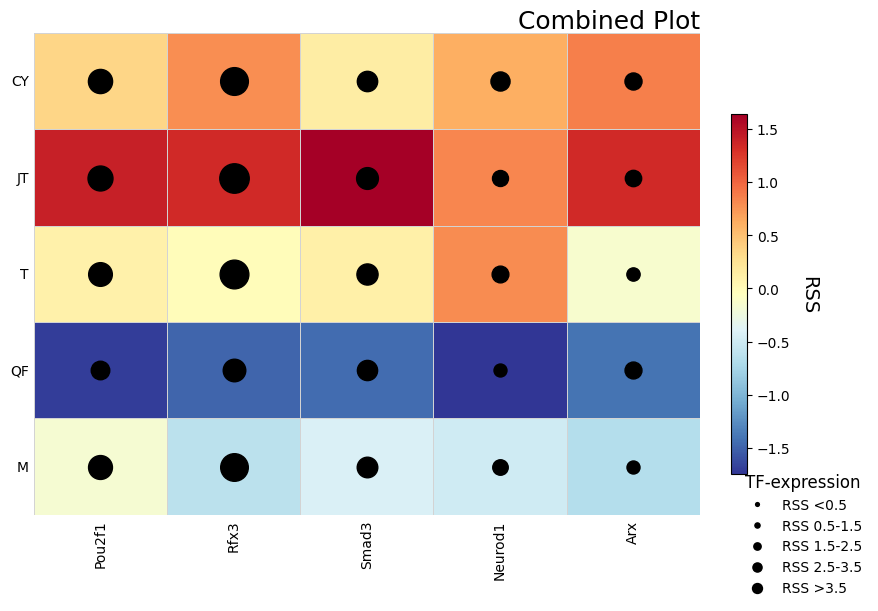

In [61]:
fig, ax = plt.subplots(1,1,figsize=(8, 6))
# 绘制数据
plot_abstract_heatmap_dots(
    ax=ax,
    heatmap_df=reg_df,
    dotplot_df=exp_df,
    title='Combined Plot', # 单张图的标题
    heatmap_color_min=HEATMAP_COLOR_MIN,
    heatmap_color_max=HEATMAP_COLOR_MAX,
    heatmap_cmap=HEATMAP_CMAP,
    dot_min_value=DOT_MIN_VALUE,
    dot_size_base=DOT_SIZE_BASE,
    dot_size_scale_factor=DOT_SIZE_SCALE_FACTOR
)

# Heatmap 颜色条
# 调整颜色条的位置，使其在单张图旁边
cbar_ax = fig.add_axes([0.92, 0.2, 0.02, 0.6]) # [left, bottom, width, height]
norm = plt.Normalize(vmin=HEATMAP_COLOR_MIN, vmax=HEATMAP_COLOR_MAX)
sm = plt.cm.ScalarMappable(cmap=HEATMAP_CMAP, norm=norm)
sm.set_array([]) # 必需设置一个空数组
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('RSS', rotation=270, labelpad=20, fontsize=14)
cbar.ax.tick_params(labelsize=10)

# Dot plot 大小图例
# 调整图例的位置，使其在单张图旁边
legend_elements = []
max_dot_val_for_legend = exp_df.max().max() # 获取当前图的最大点值用于图例映射

for label, threshold_val in dot_legend_thresholds.items():
    if threshold_val < DOT_MIN_VALUE:
        s_val = DOT_SIZE_BASE / 2
    else:
        normalized_threshold = (threshold_val - DOT_MIN_VALUE) / (max_dot_val_for_legend - DOT_MIN_VALUE)
        s_val = normalized_threshold * DOT_SIZE_SCALE_FACTOR + DOT_SIZE_BASE
        
    legend_elements.append(plt.Line2D([0], [0], marker='o', color='w',
                                    markerfacecolor='black',
                                    markersize=np.sqrt(s_val)/2, # markersize 是半径，s 是面积
                                    label=f'RSS {label}'))

legend_ax = fig.add_axes([0.92, 0.05, 0.05, 0.1]) # [left, bottom, width, height]
legend_ax.set_axis_off()
legend_ax.legend(handles=legend_elements, loc='center left', frameon=False, title="TF-expression", fontsize=10, title_fontsize=12)
plt.tight_layout(rect=[0, 0, 0.9, 1]) # 调整布局以适应颜色条和图例
plt.savefig(f'rss_plot.pdf', bbox_inches='tight')
plt.show()